# SVM: validação cruzada estratificada

São comparadas três configurações de SVM: kernel linear (LinearSVC, C=1), kernel RBF (C=1, gamma='scale') e kernel RBF com class_weight='balanced'. Todas usam as mesmas cinco partições estratificadas, com embaralhamento e semente 42, que também são usadas pelos demais classificadores do grupo. Não há reamostragem.

In [1]:
from pathlib import Path
import re
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline

raiz = Path.cwd().resolve()
if not (raiz / "dados").is_dir():
    raiz = raiz.parent
if not (raiz / "dados").is_dir():
    raise FileNotFoundError("Execute o notebook a partir da raiz do projeto ou da pasta script.")
sys.path.insert(0, str(raiz / "src"))

from preprocessamento import (carregar_dados, preparar_dados, criar_preprocessador,
                              criar_particoes, NUMERICAS, CATEGORICAS)
from avaliacao import avaliar_modelo

saida = raiz / "resultados"
saida.mkdir(exist_ok=True)

In [ ]:
caminho = raiz / "dados" / "online_shoppers_convertido.csv"
dados = carregar_dados(caminho)
print("Dimensões da base convertida:", dados.shape)
print("Duplicatas exatas:", dados.duplicated().sum())
print("Valores ausentes:", dados.isna().sum().sum())
display(dados.head())

X, y = preparar_dados(dados) 
particoes = criar_particoes(X, y)  # mesmas partições dos demais classificadores (KNN)
print("Registros após remover duplicatas:", len(X))
print("Atributos numéricos:", NUMERICAS)
print("Atributos categóricos:", CATEGORICAS)
print("Distribuição após remoção das duplicatas:")
display(y.value_counts().sort_index().rename(index={0: "Sem compra", 1: "Compra"}).to_frame("quantidade"))
print("Número de partições estratificadas:", len(particoes))

Dimensões da base convertida: (12330, 18)
Duplicatas exatas: 125
Valores ausentes: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,1,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,1,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,1,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,1,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,1,1,0


Registros após remover duplicatas: 12205
Atributos numéricos: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Atributos categóricos: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Distribuição após remoção das duplicatas:


,quantidade
Revenue,
Sem compra,10297
Compra,1908


Número de partições estratificadas: 5


In [ ]:
configuracoes = {
    "SVM linear, C=1": LinearSVC(C=1, max_iter=10000, random_state=42),
    "SVM RBF, C=1": SVC(kernel="rbf", C=1, gamma="scale"),
    "SVM RBF, C=1, balanceado": SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"),
}
resultados = []
matrizes = {}

for nome, classificador in configuracoes.items(): # percorre cada configuração
    modelo = Pipeline([  # monta o pipeline de pre processamento + classificador
        ("preprocessamento", criar_preprocessador()),
        ("modelo", classificador),
    ])
    metricas, matrizes[nome] = avaliar_modelo(modelo, X, y, particoes)
    resultados.append(metricas.reset_index().assign(configuracao=nome))
    print("Concluído:", nome)

Concluído: SVM linear, C=1
Concluído: SVM RBF, C=1
Concluído: SVM RBF, C=1, balanceado


In [ ]:
por_fold = pd.concat(resultados, ignore_index=True).rename(columns={ # junta as tabelas das 3 configurações em uma só e renomeia colunas
    "Fold": "fold", "Acurácia": "acuracia", "Precisão": "precisao",
    "Recall": "revocacao", "F1-score": "f1",
})
por_fold = por_fold[["configuracao", "fold", "acuracia", "precisao", "revocacao", "f1"]]
resumo = por_fold.groupby("configuracao")[["acuracia", "precisao", "revocacao", "f1"]].agg(["mean", "std"])

print("Métricas por partição:")
display(por_fold.round(4))
print("Média e desvio padrão entre as cinco partições:")
display(resumo.round(4))

por_fold.to_csv(saida / "svm_metricas_por_fold.csv", index=False, encoding="utf-8-sig")
resumo.to_csv(saida / "svm_metricas_resumo.csv", encoding="utf-8-sig")

Métricas por partição:


,configuracao,fold,acuracia,precisao,revocacao,f1
0,"SVM linear, C=1",1,0.8832,0.7824,0.3491,0.4828
1,"SVM linear, C=1",2,0.8771,0.7425,0.3255,0.4526
2,"SVM linear, C=1",3,0.8808,0.7791,0.3325,0.4661
3,"SVM linear, C=1",4,0.8816,0.7751,0.3429,0.4755
4,"SVM linear, C=1",5,0.8742,0.7419,0.3010,0.4283
5,"SVM RBF, C=1",1,0.8968,0.7549,0.5013,0.6025
6,"SVM RBF, C=1",2,0.8927,0.7352,0.4882,0.5868
7,"SVM RBF, C=1",3,0.8947,0.7660,0.4712,0.5835
8,"SVM RBF, C=1",4,0.8955,0.7361,0.5183,0.6083
9,"SVM RBF, C=1",5,0.8914,0.7468,0.4634,0.5719


Média e desvio padrão entre as cinco partições:


acuracia         precisao         revocacao          \
                             mean     std     mean     std      mean     std   
configuracao                                                                   
SVM RBF, C=1               0.8942  0.0022   0.7478  0.0130    0.4885  0.0223   
SVM RBF, C=1, balanceado   0.8670  0.0071   0.5549  0.0172    0.7579  0.0157   
SVM linear, C=1            0.8794  0.0037   0.7642  0.0202    0.3302  0.0187   

                              f1          
                            mean     std  
configuracao                              
SVM RBF, C=1              0.5906  0.0148  
SVM RBF, C=1, balanceado  0.6406  0.0155  
SVM linear, C=1           0.4610  0.0215

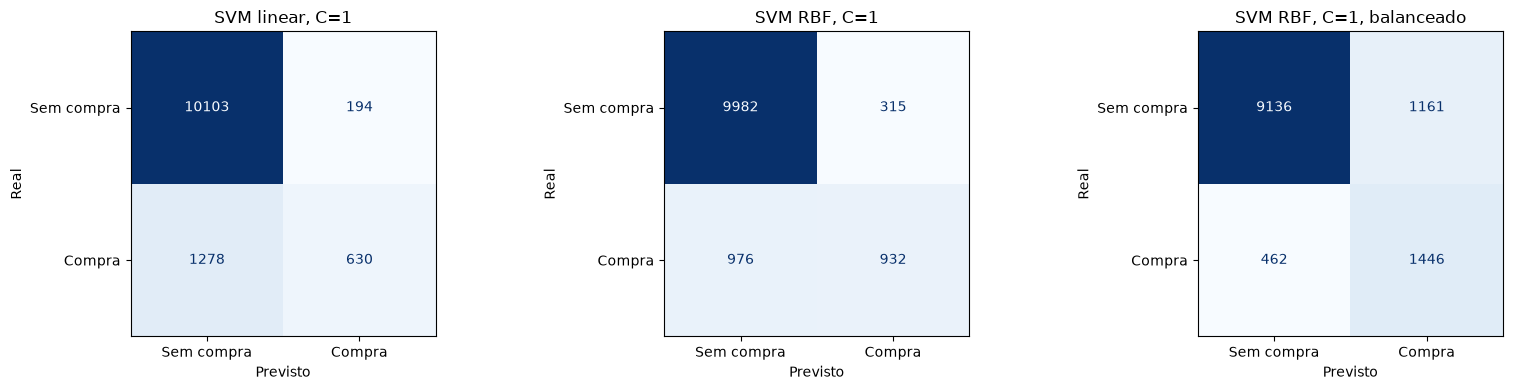

In [ ]:
fig, eixos = plt.subplots(1, len(matrizes), figsize=(5.5 * len(matrizes), 4)) # monta matriz de confusão para cada configuração
for eixo, (nome, matriz) in zip(eixos, matrizes.items()):
    ConfusionMatrixDisplay(matriz, display_labels=["Sem compra", "Compra"]).plot(
        ax=eixo, cmap="Blues", colorbar=False, values_format="d"
    )
    eixo.set_title(nome)
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")
    sufixo = re.sub(r"[^a-z0-9]+", "_", nome.lower()).strip("_")
    pd.DataFrame(matriz, index=["real_sem_compra", "real_compra"],
                 columns=["previsto_sem_compra", "previsto_compra"]).to_csv(
                     saida / f"matriz_{sufixo}.csv", encoding="utf-8-sig")
plt.tight_layout()
plt.savefig(saida / "matrizes_confusao_svm.png", dpi=300)
plt.show()